In [2]:
import pandas as pd, numpy as np

df = pd.read_csv('dirty_cafe_sales.csv', dtype=str, keep_default_na=False)
print(df.shape)   # (10000, 8)
print(df.head())

(10000, 8)
  Transaction ID    Item Quantity Price Per Unit Total Spent  Payment Method  \
0    TXN_1961373  Coffee        2            2.0         4.0     Credit Card   
1    TXN_4977031    Cake        4            3.0        12.0            Cash   
2    TXN_4271903  Cookie        4            1.0       ERROR     Credit Card   
3    TXN_7034554   Salad        2            5.0        10.0         UNKNOWN   
4    TXN_3160411  Coffee        2            2.0         4.0  Digital Wallet   

   Location Transaction Date  
0  Takeaway       2023-09-08  
1  In-store       2023-05-16  
2  In-store       2023-07-19  
3   UNKNOWN       2023-04-27  
4  In-store       2023-06-11  


In [4]:
MISSING = ['', 'ERROR', 'UNKNOWN']
for col in df.columns:
    s = df[col].str.strip().str.upper()
    print(f'{col:18} missing={s.isin(MISSING).sum():5}  unique={s.nunique()}')

print('duplicate IDs:', df['Transaction ID'].duplicated().sum())
print(df['Item'].value_counts())

Transaction ID     missing=    0  unique=10000
Item               missing=  969  unique=11
Quantity           missing=  479  unique=8
Price Per Unit     missing=  533  unique=9
Total Spent        missing=  502  unique=20
Payment Method     missing= 3178  unique=6
Location           missing= 3961  unique=5
Transaction Date   missing=  460  unique=368
duplicate IDs: 0
Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
             333
ERROR        292
Name: count, dtype: int64


In [5]:
df = df.apply(lambda s: s.str.strip())
df = df.replace({'': np.nan, 'ERROR': np.nan, 'UNKNOWN': np.nan})

for c in ['Quantity', 'Price Per Unit', 'Total Spent']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'], errors='coerce')

In [6]:
ok = df.dropna(subset=['Item', 'Price Per Unit'])
print(pd.crosstab(ok['Item'], ok['Price Per Unit']))   # one price per item

full = df.dropna(subset=['Quantity', 'Price Per Unit', 'Total Spent'])
print('rule broken:', (full['Quantity'] * full['Price Per Unit'] != full['Total Spent']).sum())  # 0

Price Per Unit   1.0   1.5   2.0   3.0   4.0   5.0
Item                                              
Cake               0     0     0  1085     0     0
Coffee             0     0  1108     0     0     0
Cookie          1026     0     0     0     0     0
Juice              0     0     0  1110     0     0
Salad              0     0     0     0     0  1082
Sandwich           0     0     0     0  1082     0
Smoothie           0     0     0     0  1036     0
Tea                0  1023     0     0     0     0
rule broken: 0


In [7]:
MENU = {'Cookie':1.0, 'Tea':1.5, 'Coffee':2.0, 'Cake':3.0,
        'Juice':3.0, 'Sandwich':4.0, 'Smoothie':4.0, 'Salad':5.0}
UNIQUE_PRICE = {1.0:'Cookie', 1.5:'Tea', 2.0:'Coffee', 5.0:'Salad'}

for _ in range(2):   # two passes so one fix can unlock another
    m = df['Price Per Unit'].isna() & df['Item'].notna()
    df.loc[m, 'Price Per Unit'] = df.loc[m, 'Item'].map(MENU)

    m = df['Total Spent'].isna() & df['Quantity'].notna() & df['Price Per Unit'].notna()
    df.loc[m, 'Total Spent'] = df['Quantity'] * df['Price Per Unit']

    m = df['Quantity'].isna() & df['Total Spent'].notna() & df['Price Per Unit'].notna()
    df.loc[m, 'Quantity'] = df['Total Spent'] / df['Price Per Unit']

    m = df['Price Per Unit'].isna() & df['Total Spent'].notna() & df['Quantity'].notna()
    df.loc[m, 'Price Per Unit'] = df['Total Spent'] / df['Quantity']

    m = df['Item'].isna() & df['Price Per Unit'].map(UNIQUE_PRICE).notna()
    df.loc[m, 'Item'] = df.loc[m, 'Price Per Unit'].map(UNIQUE_PRICE)

In [8]:
for c in ['Item', 'Payment Method', 'Location']:
    df[c] = df[c].fillna('Unknown')
df['Quantity'] = df['Quantity'].round().astype('Int64')

print(df.isna().sum())   # Quantity 23, Price 6, Total 23, Date 460
print((df[['Item', 'Payment Method', 'Location']] == 'Unknown').sum())   # 480, 3178, 3961

Transaction ID        0
Item                  0
Quantity             23
Price Per Unit        6
Total Spent          23
Payment Method        0
Location              0
Transaction Date    460
dtype: int64
Item               480
Payment Method    3178
Location          3961
dtype: int64


In [9]:
r = df[df['Total Spent'].notna()]          # priced orders only
print(r['Total Spent'].sum(), len(r), r['Total Spent'].mean().round(2), r['Quantity'].sum())

by_item = (r.groupby('Item')
             .agg(orders=('Total Spent', 'size'), units=('Quantity', 'sum'),
                  revenue=('Total Spent', 'sum'), aov=('Total Spent', 'mean'))
             .sort_values('revenue', ascending=False))
by_item['share_pct'] = (by_item['revenue'] / by_item['revenue'].sum() * 100).round(1)
print(by_item)

dated = r.dropna(subset=['Transaction Date'])
by_month = dated.groupby(dated['Transaction Date'].dt.to_period('M'))['Total Spent'].sum()
by_weekday = dated.groupby(dated['Transaction Date'].dt.day_name())['Total Spent'].sum()
by_payment = r.groupby('Payment Method')['Total Spent'].agg(['size', 'sum', 'mean'])
by_qty = r.groupby('Quantity')['Total Spent'].agg(['size', 'sum'])

# Do payment methods really differ in order value? (non-parametric test)
from scipy import stats
known = r[r['Payment Method'] != 'Unknown']
print(stats.kruskal(*[g['Total Spent'] for _, g in known.groupby('Payment Method')]))  # p about 0.79

89096.0 9977 8.93 30170
          orders  units  revenue        aov  share_pct
Item                                                  
Salad       1270   3819  19095.0  15.035433       21.4
Sandwich    1127   3429  13716.0  12.170364       15.4
Smoothie    1094   3336  13344.0  12.197441       15.0
Juice       1168   3505  10515.0   9.002568       11.8
Cake        1138   3468  10404.0   9.142355       11.7
Coffee      1286   3904   7808.0   6.071540        8.8
Tea         1206   3650   5475.0   4.539801        6.1
Unknown      477   1461   5141.0  10.777778        5.8
Cookie      1211   3598   3598.0   2.971098        4.0
KruskalResult(statistic=np.float64(0.4733518258300405), pvalue=np.float64(0.7892470313435338))


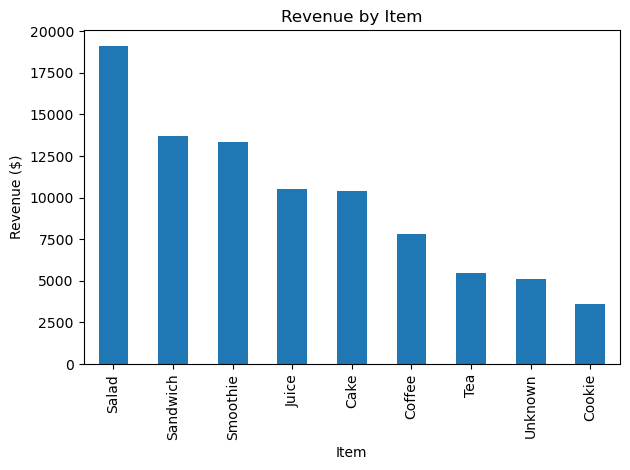

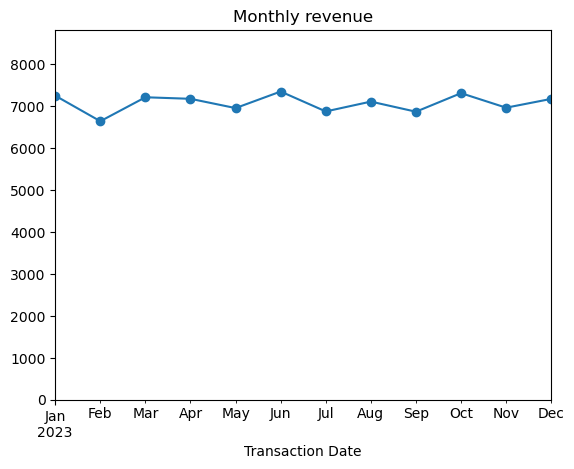

In [10]:
import matplotlib.pyplot as plt

by_item['revenue'].plot(kind='bar', title='Revenue by Item')
plt.ylabel('Revenue ($)'); plt.tight_layout(); plt.show()

by_month.plot(kind='line', marker='o', title='Monthly revenue')
plt.ylim(0, by_month.max() * 1.2); plt.show()    # start at 0 so the chart is honest

df.to_csv('cleaned_cafe_sales.csv', index=False)